# Jupyter Explained · QuantStack
*No hype. Just code.*

Companion notebook for the series. Run it top to bottom with **Kernel → Restart Kernel and Run All Cells**.

| Part | Topic |
|---|---|
| 1 | What Jupyter is, install Anaconda, launch it |
| 2 | Environments and kernels |
| 3 | The JupyterLab interface: menus, panels, tools |
| 4 | Working in a notebook: cells, modes, shortcuts, the kernel menu |
| 5 | Power tools: magics, debugger, widgets, extensions |
| 6 | Sharing, exporting and keeping it safe |


---
# Part 1 · What Jupyter is, install Anaconda, launch it

## 1.1 The kernel remembers
Three cells and a check. Run them once, top to bottom, and the check passes.

**To see the problem:** click the cell that adds 1 and run it two more times with **Ctrl+Enter**, then run the last cell and the check. The check fails. Then use **Kernel → Restart Kernel and Run All Cells** and it passes again.

In [1]:
count = 0

In [2]:
count += 1   # run this cell once

In [3]:
count

1

In [4]:
assert count == 1, "Hidden state: a cell was run more than once. Restart the kernel and Run All."
print("OK: count is", count)

OK: count is 1


## 1.2 Which Python is this notebook really using?
The kernel is a separate program. This prints which one it is. Part 2 uses this cell again.

In [5]:
import sys, platform
print("Python version :", sys.version.split()[0])
print("Python program :", sys.executable)
print("Operating system:", platform.system(), platform.release())

Python version : 3.14.6
Python program : C:\Users\quantstack\anaconda3\python.exe
Operating system: Windows 10


In [6]:
!jupyter --version

Selected Jupyter core packages...
IPython          : 9.15.0
ipykernel        : 6.31.0
ipywidgets       : 8.1.7
jupyter_client   : 8.9.1
jupyter_core     : 5.9.1
jupyter_server   : 2.20.0
jupyterlab       : 4.5.9
nbclient         : 0.11.0
nbconvert        : 7.17.1
nbformat         : 5.10.4
notebook         : 7.5.7
qtconsole        : 5.7.2
traitlets        : 5.15.0


## 1.3 Your first cells
Run each with **Shift+Enter**. The number in the brackets counts the order you ran things in.

In [7]:
1 + 2

3

In [8]:
3 * 4

12

In [9]:
5 - 2

3

In [10]:
assert (1 + 2, 3 * 4, 5 - 2) == (3, 12, 3)
print("OK: all three results match")

OK: all three results match


---
# Part 2 · Environments and kernels

## 2.1 Which environment is this kernel?
A kernel runs one Python. This prints which one. In the base environment the name shows the install folder's name. In a named environment it shows that environment's name.

In [11]:
import sys, os
from pathlib import Path

def which_env():
    """Describe the Python this kernel is running."""
    prefix = Path(sys.prefix)
    return {
        "env_name": prefix.name,
        "prefix": str(prefix),
        "python": sys.executable,
        "version": sys.version.split()[0],
        "is_conda_env": (prefix / "conda-meta").exists(),
    }

info = which_env()
for key, value in info.items():
    print(f"{key:13}: {value}")

assert info["env_name"] == Path(sys.prefix).name
assert isinstance(info["is_conda_env"], bool)

env_name     : anaconda3
prefix       : C:\Users\quantstack\anaconda3
python       : C:\Users\quantstack\anaconda3\python.exe
version      : 3.14.6
is_conda_env : True


## 2.2 Can this kernel import a package?
Run this in each kernel. The check at the bottom tests the helper itself, not your packages.

In [12]:
import importlib.util

def has_package(name):
    """True if this kernel can import the package."""
    return importlib.util.find_spec(name) is not None

PACKAGES = ["numpy", "pandas", "matplotlib"]
for name in PACKAGES:
    print("OK     " if has_package(name) else "MISSING", name)

assert has_package("json") and not has_package("this_package_does_not_exist_12345")

OK      numpy
OK      pandas
OK      matplotlib


## 2.3 Installing into this kernel's environment
Use the percent forms from inside a notebook. They are commented out here so Restart and Run All stays safe. Uncomment one, run it, then rerun 2.2.

In [13]:
# %pip install numpy
# %conda install numpy

---
# Part 3 · The JupyterLab interface

## 3.1 Demo files to open in JupyterLab
This writes a small folder with a table, a data file, a markdown note, a text file and a small Python file. Open each one from the file browser and see which viewer it uses.

In [14]:
from pathlib import Path
import json, csv

DEMO = Path("demo_files")

def make_demo_files(folder=DEMO):
    folder.mkdir(exist_ok=True)
    with open(folder / "table.csv", "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["day", "count"])
        writer.writerows([[1, 4], [2, 7], [3, 5]])
    (folder / "data.json").write_text(json.dumps({"name": "demo", "values": [1, 2, 3], "nested": {"ok": True}}, indent=2))
    (folder / "note.md").write_text("# Demo note\n\nThis is **markdown**.\n\n- one\n- two\n")
    (folder / "plain.txt").write_text("Just plain text.\n")
    (folder / "script.py").write_text("a = 10\nb = 20\nprint(a + b)\n")
    return sorted(p.name for p in folder.iterdir())

files = make_demo_files()
print(files)
assert files == ["data.json", "note.md", "plain.txt", "script.py", "table.csv"]

['data.json', 'note.md', 'plain.txt', 'script.py', 'table.csv']


In [15]:
import shutil
# shutil.rmtree(DEMO)   # uncomment and run to remove the demo folder when you are done

---
# Part 4 · Working in a notebook

## 4.1 Why a page can show two answers
Run these cells once, top to bottom. Then change the experiment cell to `width = 10`, run **only that cell**, and run the check. The check fails, because `area` was never recalculated. Restart and Run All fixes it.

In [16]:
width = 4

In [17]:
area = width * 5

In [18]:
area

20

In [19]:
width = 4   # change this to 10 and run only this cell

In [20]:
assert area == width * 5, "Stale: area was computed with an old width. Run the cells above again."

## 4.2 Markdown showcase
Double-click this cell to see its source. Press Shift+Enter to render it again.

#### A small heading

Some *italic* and **bold** text, and `inline code`.

- first item
- second item

1. step one
2. step two

[A link](https://jupyter.org)

[Jump to the target heading](#Jump-target)

| day | count |
|---|---|
| 1 | 4 |
| 2 | 7 |

Math: $a^2 + b^2 = c^2$

## Jump target
This heading is the target of the link in 4.2. Click the link there, and the notebook scrolls here.

## 4.3 Interrupting a stuck cell
Uncomment the sleep, run the cell, then use Kernel → Interrupt Kernel. Re-comment it before you save.

In [21]:
import time
print("Ready.")
# time.sleep(300)   # uncomment, run, then Kernel -> Interrupt Kernel

Ready.


## 4.4 Reading an error
Uncomment the line, run the cell, and read the traceback from the bottom. Re-comment it before you save.

In [22]:
print("This cell has a commented-out error.")
# 1 / 0   # uncomment and run to see a ZeroDivisionError traceback

This cell has a commented-out error.


## 4.5 When the kernel dies
Only in a **throwaway** notebook: uncomment the line, run it, and watch the kernel die and restart. Re-comment it before you save.

In [23]:
import os
# os._exit(0)   # kills the kernel on purpose: uncomment in a throwaway notebook only

---
# Part 5 · Power tools

## 5.1 Don't guess, measure
Two ways to add up a thousand numbers. The check proves they agree before we time them. Timing results vary by machine, so read them off your own screen.

In [24]:
numbers = list(range(1000))

def total_loop(values):
    total = 0
    for v in values:
        total += v
    return total

def total_builtin(values):
    return sum(values)

assert total_loop(numbers) == total_builtin(numbers) == 499500

In [25]:
%timeit total_loop(numbers)

27.7 μs ± 269 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [26]:
%timeit total_builtin(numbers)

3.42 μs ± 124 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


In [27]:
%%time
total_builtin(numbers)

CPU times: total: 0 ns
Wall time: 9.78 μs


499500

## 5.2 Write a file, then import it
`%%writefile` must be the first line of the cell.

In [28]:
%%writefile helper.py
def add(a, b):
    return a + b

Overwriting helper.py


In [29]:
import helper
assert helper.add(2, 3) == 5
helper.add(2, 3)

5

### 5.2b Reload edited modules without restarting
After this, edits you save to `helper.py` are picked up the next time you run a cell.

In [30]:
%load_ext autoreload
%autoreload 2

## 5.3 Clean up
Uncomment to remove the helper file and its cache folder when you are done.

In [31]:
import os, shutil
# os.remove("helper.py")
# shutil.rmtree("__pycache__", ignore_errors=True)

## 5.4 Rich output, a progress bar and a slider
Each cell skips politely if its package is missing from this kernel's environment (see Part 2).

In [32]:
from IPython.display import display, Markdown

try:
    import pandas as pd
    df = pd.DataFrame({"day": [1, 2, 3], "count": [4, 7, 5]})
    display(df)
    assert int(df["count"].sum()) == 16
except ImportError:
    print("MISSING PACKAGE: pandas. Install it into this kernel's environment (Part 2).")

display(Markdown("A line of **rendered** text from `display()`."))

,day,count
0,1,4
1,2,7
2,3,5


A line of **rendered** text from `display()`.

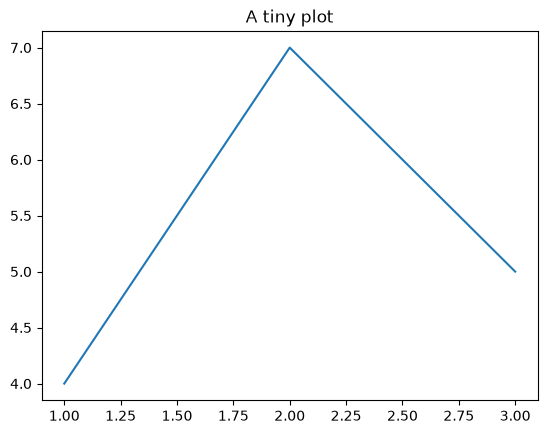

In [33]:
try:
    import matplotlib.pyplot as plt
    plt.plot([1, 2, 3], [4, 7, 5])
    plt.title("A tiny plot")
    plt.show()
except ImportError:
    print("MISSING PACKAGE: matplotlib. Install it into this kernel's environment (Part 2).")

In [34]:
try:
    from tqdm import tqdm
    import time
    for _ in tqdm(range(20)):
        time.sleep(0.02)
except ImportError:
    print("MISSING PACKAGE: tqdm. Install it into this kernel's environment (Part 2).")

100%|██████████| 20/20 [00:00<00:00, 47.52it/s]


In [35]:
try:
    from ipywidgets import interact

    @interact(x=(0, 10))
    def square(x=3):
        print(x * x)
except ImportError:
    print("MISSING PACKAGE: ipywidgets. Install it into this kernel's environment (Part 2).")

interactive(children=(IntSlider(value=3, description='x', max=10), Output()), _dom_classes=('widget-interact',…

## 5.5 Debugging a deliberate bug
Uncomment the check, run it (it fails), then run `%debug` in the next cell and look at `values` and `len(values)`.

In [36]:
def average(values):
    """Deliberate bug: divides by one too many."""
    return sum(values) / (len(values) + 1)

# assert average([2, 4, 6]) == 4   # uncomment and run: it fails

In [37]:
# %debug   # uncomment and run right after the failing cell

## 5.6 More magics
Folder magics, the plotting magic, an HTML cell, and the last-output shortcut.

In [38]:
%pwd

'C:\\Users\\quantstack'

In [39]:
%ls

 Volume in drive C has no label.
 Volume Serial Number is C284-F073

 Directory of C:\Users\quantstack

11/06/2026  07:42 PM    <DIR>          .
11/06/2026  07:42 PM    <DIR>          ..
11/06/2026  07:33 AM    <DIR>          .anaconda
11/06/2026  06:57 PM    <DIR>          .conda
11/06/2026  07:33 AM    <DIR>          .continuum
06/02/2026  06:27 PM    <DIR>          .frameio
11/06/2026  06:59 AM    <DIR>          .idea
11/06/2026  06:59 AM    <DIR>          .ipynb_checkpoints
11/06/2026  06:59 AM    <DIR>          .ipython
11/06/2026  06:59 AM    <DIR>          .jupyter
11/06/2026  06:05 PM                33 .python_history
11/06/2026  10:52 AM    <DIR>          .smplayer
11/06/2026  06:56 PM    <DIR>          .virtual_documents
11/06/2026  07:42 PM    <DIR>          __pycache__
11/06/2026  06:51 AM    <DIR>          3D Objects
11/06/2026  06:51 PM    <DIR>          anaconda3
11/06/2026  07:32 AM    <DIR>          assets
11/06/2026  06:22 PM            20,964 atomx-unlock.log
11/06/2

In [40]:
%matplotlib inline

In [41]:
%%HTML
<b>Rendered</b> as HTML

In [42]:
7 * 6

42

In [43]:
print(_)   # the last output, here 42

19


---
# Part 6 · Sharing, exporting and keeping it safe

## 6.1 Before you share
1. **Restart and Run All** so you know it runs from the top.
2. **Keep or clear outputs** (Edit → Clear All Outputs).
3. **Check what is in the file** (6.2 below).
4. **Fix the findings, then check again.**

## 6.2 A checker for tokens, paths and password-looking lines
It reads the notebook as data and matches a few patterns in every cell's code and saved output. It only finds the patterns it knows. A secret that does not look like one will pass.

In [44]:
import json, re
from pathlib import Path

PATTERNS = {
    "token in URL": re.compile(r"[?&]token=[0-9a-fA-F]{8,}"),
    "home folder path": re.compile(r"(?:[A-Za-z]:\\Users\\|/Users/|/home/)[^\s\"']+"),
    "password-style assignment": re.compile(r"(?i)\b(?:api[_-]?key|secret|password)\s*=\s*['\"][^'\"]{6,}['\"]"),
}

def _texts(cell):
    yield "".join(cell.get("source", []))
    for out in cell.get("outputs", []):
        yield "".join(out.get("text", []))
        for value in out.get("data", {}).values():
            yield "".join(value) if isinstance(value, list) else str(value)

def scan_notebook(nb):
    """Return a sorted list of (cell_index, label) findings."""
    found = set()
    for i, cell in enumerate(nb.get("cells", [])):
        for text in _texts(cell):
            for label, pattern in PATTERNS.items():
                if pattern.search(text):
                    found.add((i, label))
    return sorted(found)

In [45]:
# SYNTHETIC notebook with FAKE values, built on purpose to be flagged.
FAKE = {
    "cells": [
        {"cell_type": "code", "source": ["print('hello')\n"], "outputs": []},
        {"cell_type": "code", "source": ["api_key = 'FAKE-KEY-123456'\n"], "outputs": []},
        {"cell_type": "code", "source": ["print(url)\n"], "outputs": [
            {"output_type": "stream", "name": "stdout",
             "text": ["http://localhost:8888/lab?token=0123456789abcdef0123\n"]}]},
        {"cell_type": "code", "source": ["print(path)\n"], "outputs": [
            {"output_type": "stream", "name": "stdout",
             "text": ["C:\\Users\\demo\\Documents\\data.csv\n"]}]},
    ]
}
CLEAN = {"cells": [{"cell_type": "code", "source": ["x = 1\n"], "outputs": []}]}

expected = [(1, "password-style assignment"), (2, "token in URL"), (3, "home folder path")]
assert scan_notebook(FAKE) == expected
assert scan_notebook(CLEAN) == []
for item in scan_notebook(FAKE):
    print(item)

(1, 'password-style assignment')
(2, 'token in URL')
(3, 'home folder path')


## 6.3 Scan a real notebook
Set the path to a notebook file and run the cell. Read each finding, fix it in the source, and scan again.

In [46]:
NOTEBOOK_PATH = None   # for example "my_notebook.ipynb"

if NOTEBOOK_PATH:
    nb = json.loads(Path(NOTEBOOK_PATH).read_text(encoding="utf-8"))
    findings = scan_notebook(nb)
    print(f"{len(findings)} finding(s)")
    for item in findings:
        print(item)
else:
    print("Set NOTEBOOK_PATH to a notebook file to scan it.")

Set NOTEBOOK_PATH to a notebook file to scan it.


---
# Bonus · Habits that stop notebooks lying

## B.1 The habit checklist
1. **Write it to run top to bottom.** Imports and settings first, one job per cell.
2. **Restart and Run All** before you save or share.
3. **Read the counters.** A higher number above a lower one means the cells ran out of order.
4. **Keep checks in the notebook.** An `assert` fails loudly when a number is wrong.
5. **Pin the environment.** Keep an `environment.yml` next to the notebook.
6. **Never print secrets.** Read keys from the environment, not from a cell.
7. **Clean and scan before sharing** (section 6.2).
8. **Say what you changed.** Use short markdown notes at each step.

## B.2 A check for the counters
A clean Restart and Run All gives counters 1, 2, 3 and so on, in order. This function checks a notebook file's saved counters. It is tested below on small synthetic examples.

In [47]:
def counters_in_order(nb):
    """True if the saved execution counters run 1, 2, 3 ... top to bottom with no gaps or repeats."""
    counts = [c.get("execution_count") for c in nb.get("cells", [])
              if c.get("cell_type") == "code" and c.get("execution_count") is not None]
    return counts == list(range(1, len(counts) + 1))

def _nb(counts):
    return {"cells": [{"cell_type": "code", "execution_count": n, "source": [], "outputs": []} for n in counts]}

assert counters_in_order(_nb([1, 2, 3]))            # a clean run
assert not counters_in_order(_nb([1, 3, 2]))        # run out of order
assert not counters_in_order(_nb([1, 2, 2]))        # a cell run twice
assert not counters_in_order(_nb([2, 3, 4]))        # not a fresh kernel
print("OK: the counter check behaves as expected")

OK: the counter check behaves as expected


## B.3 Check a real notebook
Set `NOTEBOOK_PATH` in section 6.3 first. This reuses the secret scanner from 6.2.

In [48]:
if NOTEBOOK_PATH:
    nb_check = json.loads(Path(NOTEBOOK_PATH).read_text(encoding="utf-8"))
    print("counters in order:", counters_in_order(nb_check))
    print("secret scan findings:", scan_notebook(nb_check))
else:
    print("Set NOTEBOOK_PATH in section 6.3 to check a real notebook.")

Set NOTEBOOK_PATH in section 6.3 to check a real notebook.
